# 01 — Descriptive Analysis of the Digikala Review Dataset (Part A)

**Project 3 — Phase 1.** This notebook presents the Part A (A1–A7) evidence that justifies the modeling decisions in Parts B and C.

**How this notebook works.** Every global count was computed on the *complete* dataset by the scripts in `src/` (Polars, streaming) and saved to `artifacts/eda/*.json` and `reports/figures/*.png`. This notebook only *loads* those artifacts, so it runs in seconds and the numbers cannot drift from the scripts. Re-run `python src/step_*.py` from the repository root to regenerate them.

**Language:** the narrative is in English; terminal outputs and review texts stay in Persian.

| Step | Script | Artifact | Data used |
|---|---|---|---|
| Step 0 (quality gate, Parquet) | `step0_ingest.py` | `step0_summary.json` | full raw CSV |
| Dedup policy | `dedup.py`, `audit_verification.py` | `dedup_policy.json`, `verification_6points.json` | full raw data |
| A1 size and structure | `step_a1.py`, `step_a1_schema.py` | `A1_schema_and_dtypes.json`, `step_a1_product_dist.json` | full raw and clean |
| A2 missing values | `step_a2.py` | `step_a2_missing.json` | full raw and clean |
| A3 targets | `step_a3.py` | `step_a3_targets.json` | full clean |
| A4 text length | `step_a4.py` | `step_a4_text_length.json` | chars/words: full clean; **tokens: sample N=200,000, seed 2026** |
| A5 repetition, conflicts, concentration | `step_a5.py` | `step_a5_repetition_concentration.json` | full clean (leakage simulation uses a hash split, seed 2026, illustration only) |
| A6 vocabulary (optional extension) | `step_a6.py` | `step_a6_vocabulary.json` | **sample N=1,000,000, seed 2026** |

Unless stated otherwise, "clean" means the dataset after the deduplication policy (6,152,858 rows).

In [1]:
%pip install polars

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install polars

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:

import json
from pathlib import Path

import polars as pl
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "artifacts").exists():      # notebook lives in notebooks/
    ROOT = ROOT.parent
EDA = ROOT / "artifacts" / "eda"
FIG = ROOT / "reports" / "figures"
pl.Config.set_tbl_rows(60)
pl.Config.set_fmt_str_lengths(80)


def load(name):
    with open(EDA / name, encoding="utf-8") as f:
        return json.load(f)


def fmt(v):
    if isinstance(v, bool) or v is None:
        return str(v)
    if isinstance(v, int):
        return f"{v:,}"
    if isinstance(v, float):
        return f"{v:,.3f}".rstrip("0").rstrip(".")
    return str(v)


def table(rows, cols=None):
    """List of dicts -> Polars DataFrame with every cell formatted as text."""
    cols = cols or list(rows[0].keys())
    return pl.DataFrame({c: [fmt(r.get(c)) for r in rows] for c in cols})


def kv(d, keys=None):
    keys = keys or list(d.keys())
    return table([{"metric": k, "value": d[k]} for k in keys])


def show_fig(name, width=1100):
    display(Image(filename=str(FIG / name), width=width))

## 0. Schema and quality gate (Step 0) and deduplication policy

The raw CSV was read with a CSV parser (not by physical lines), every column was validated, and nothing was silently coerced. The exclusions below are all documented.

In [4]:
s0 = load("step0_summary.json")
q = load("00_quality_gate_summary.json")

display(kv({"raw rows": s0["total_rows"], "unique ids": s0["unique_ids"],
            "duplicate id rows": s0["total_rows"] - s0["unique_ids"],
            "schema passed": q["schema_validation"]["schema_passed"],
            "rate out of [0,5] (count)": q["quality_counts"]["out_of_range_rate_count"],
            "body literal 'nan'": s0["text_hygiene_audit"]["body_literal_nan"],
            "title literal 'nan'": s0["text_hygiene_audit"]["title_literal_nan"],
            "recommendation_status literal 'nan'": s0["text_hygiene_audit"]["rec_literal_nan_converted_to_null"]}))
print("Out-of-range rate record(s):", s0["rate_out_of_range_records"])
print("Observed recommendation_status vocabulary:", q["recommendation_status_raw_vocabulary"])

metric,value
str,str
"""raw rows""","""6,156,289"""
"""unique ids""","""6,153,060"""
"""duplicate id rows""","""3,229"""
"""schema passed""","""True"""
"""rate out of [0,5] (count)""","""1"""
"""body literal 'nan'""","""637"""
"""title literal 'nan'""","""2,865,062"""
"""recommendation_status literal 'nan'""","""894,426"""


Out-of-range rate record(s): [{'row_idx': 4369260, 'id': 38631814, 'product_id': 5095301, 'rate': 2500.0}]
Observed recommendation_status vocabulary: [{'recommendation_status': 'recommended', 'len': 4162839}, {'recommendation_status': 'nan', 'len': 894426}, {'recommendation_status': 'no_idea', 'len': 594121}, {'recommendation_status': 'not_recommended', 'len': 504903}]


In [5]:
d = load("dedup_policy.json")
display(kv(d, ["raw_total_rows", "raw_unique_ids", "total_duplicate_ids", "cat_A_ids_count", "cat_B_ids_count",
               "cat_C_ids_count", "body_diff_whitespace_zwnj_yeh_kaf_only", "body_actual_text_diff",
               "rows_removed_from_cat_C_drop_all", "rows_removed_from_cat_AB_keep_first_valid",
               "total_rows_removed", "clean_total_rows", "formula_verified"]))

metric,value
str,str
"""raw_total_rows""","""6,156,289"""
"""raw_unique_ids""","""6,153,060"""
"""total_duplicate_ids""","""3,226"""
"""cat_A_ids_count""","""2,911"""
"""cat_B_ids_count""","""113"""
"""cat_C_ids_count""","""202"""
"""body_diff_whitespace_zwnj_yeh_kaf_only""","""87"""
"""body_actual_text_diff""","""154"""
"""rows_removed_from_cat_C_drop_all""","""404"""


**Policy.** Category A (identical) and B (differ only by null/`nan`, whitespace, ZWNJ, Arabic Yeh/Kaf) keep one row per id; Category C (real conflict in body, rate or recommendation) drops *all* copies. The invariant `clean rows = unique ids − C ids` holds.
Three products that appear with 400 raw reviews were scraped twice (200 unique ids each, all Category A), so the real scraping cap is **200 reviews per product**.

## A1. Dataset size and structure
*Data: complete raw and clean datasets.*

In [6]:
a1 = load("A1_schema_and_dtypes.json")
display(table(a1["schema"]))
keys = ["total_records", "unique_ids", "unique_products", "unique_seller_codes_excl_nan",
        "unique_seller_titles_excl_nan", "rows_without_seller", "parquet_file_size_mb"]
display(table([{"metric": k, "raw": a1["raw"][k], "clean": a1["clean"][k]} for k in keys]))
print(f"CSV size: {a1['csv_file_size_mb']} MB | Parquet (raw): {a1['raw']['parquet_file_size_mb']} MB "
      f"({a1['parquet_size_reduction_pct']}% smaller, {a1['csv_to_parquet_ratio']}x)")
print("Extra pipeline columns:", a1["extra_columns_added_by_pipeline"])

column,dtype
str,str
"""id""","""Int64"""
"""title""","""String"""
"""body""","""String"""
"""created_at""","""String"""
"""rate""","""Float64"""
"""recommendation_status""","""String"""
"""is_buyer""","""Boolean"""
"""product_id""","""Int64"""
"""advantages""","""String"""


metric,raw,clean
str,str,str
"""total_records""","""6,156,289""","""6,152,858"""
"""unique_ids""","""6,153,060""","""6,152,858"""
"""unique_products""","""331,599""","""331,598"""
"""unique_seller_codes_excl_nan""","""29,213""","""29,213"""
"""unique_seller_titles_excl_nan""","""29,228""","""29,228"""
"""rows_without_seller""","""302,181""","""301,968"""
"""parquet_file_size_mb""","""260.01""","""258.34"""


CSV size: 1219.3 MB | Parquet (raw): 260.01 MB (78.7% smaller, 4.69x)
Extra pipeline columns: ['row_idx', 'rate_out_of_range']


metric,value
str,str
"""unique_products""","""331,598"""
"""min""","""1"""
"""mean""","""18.56"""
"""std""","""40.9"""
"""p25""","""1"""
"""p50""","""4"""
"""p75""","""13"""
"""p90""","""46"""
"""p95""","""110"""


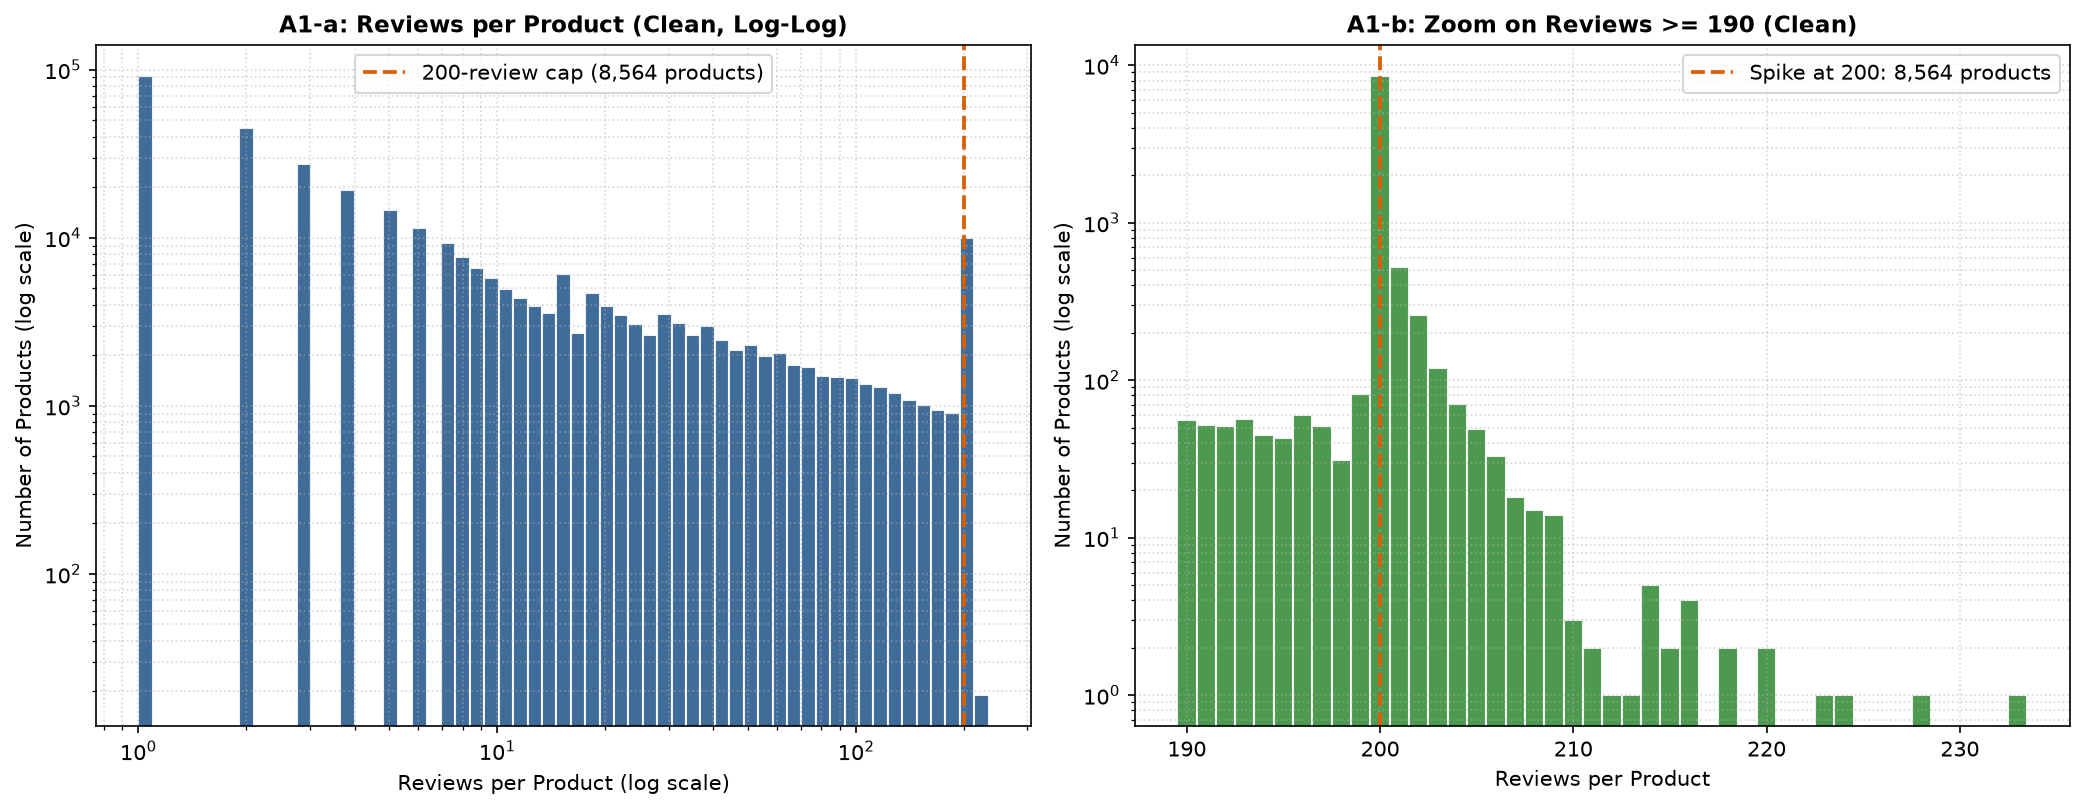

In [7]:
p = load("step_a1_product_dist.json")["clean_product_distribution"]
display(kv(p, ["unique_products", "min", "mean", "std", "p25", "p50", "p75", "p90", "p95", "p99", "max",
               "single_review_products", "exact_200_products", "over_200_products", "at_least_200_products",
               "share_of_products_ge_200_pct", "share_of_reviews_in_products_ge_200_pct"]))
show_fig("A1_product_review_distribution.png")

**Reading.** Reviews per product are extremely skewed (median 4, p99 = 200). The spike at exactly 200 is the scraper's cap: 2.9% of products (≥200 reviews) hold 31.6% of all reviews. The `title`, `advantages`, `disadvantages` and `true_to_size_rate` columns are mostly empty (see A2), but they are not model inputs anyway because only `body` is used.

## A2. Missing-value patterns
*Data: complete raw and clean datasets. Missing = null or one of `''`, `nan`, `none`, `null` after strip/lowercase.*

In [8]:
m = load("step_a2_missing.json")
rows = []
for r, c in zip(m["per_column_raw"], m["per_column_clean"]):
    rows.append({"column": r["column"], "dtype": r["dtype"], "raw_missing": r["missing_total"],
                 "raw_%": r["missing_pct"], "clean_missing": c["missing_total"], "clean_%": c["missing_pct"]})
display(table(rows))

column,dtype,raw_missing,raw_%,clean_missing,clean_%
str,str,str,str,str,str
"""id""","""Int64""","""0""","""0""","""0""","""0"""
"""title""","""String""","""2,866,415""","""46.561""","""2,864,793""","""46.56"""
"""body""","""String""","""637""","""0.01""","""637""","""0.01"""
"""created_at""","""String""","""0""","""0""","""0""","""0"""
"""rate""","""Float64""","""0""","""0""","""0""","""0"""
"""recommendation_status""","""String""","""894,426""","""14.529""","""894,045""","""14.531"""
"""is_buyer""","""Boolean""","""0""","""0""","""0""","""0"""
"""product_id""","""Int64""","""0""","""0""","""0""","""0"""
"""advantages""","""String""","""5,448,084""","""88.496""","""5,445,071""","""88.497"""


recommendation_status missing (clean): 894,045 / 6,152,858 = 14.531%


factor,cramers_v,min_missing_%_(groups n>=1000),max_missing_%_(groups n>=1000)
str,str,str,str
"""is_buyer""","""0.551""","""10.12""","""100"""
"""rate_bucket""","""0.114""","""4.91""","""18.12"""
"""prod_bucket""","""0.057""","""12.6""","""20.31"""
"""year""","""0.279""","""4.78""","""97.4"""
"""body_len_bucket""","""0.057""","""12.72""","""17.7"""



Missing label by is_buyer


is_buyer,n,missing,missing_pct
str,str,str,str
"""false""","""301,968""","""301,968""","""100"""
"""true""","""5,850,890""","""592,077""","""10.12"""



Missing label by year


year,n,missing,missing_pct
str,str,str,str
"""1395""","""3,561""","""3,458""","""97.11"""
"""1396""","""6,342""","""6,177""","""97.4"""
"""1397""","""16,679""","""8,010""","""48.02"""
"""1398""","""138,595""","""18,640""","""13.45"""
"""1399""","""684,176""","""38,497""","""5.63"""
"""1400""","""1,253,289""","""59,902""","""4.78"""
"""1401""","""2,165,222""","""569,038""","""26.28"""
"""1402""","""1,884,994""","""190,323""","""10.1"""


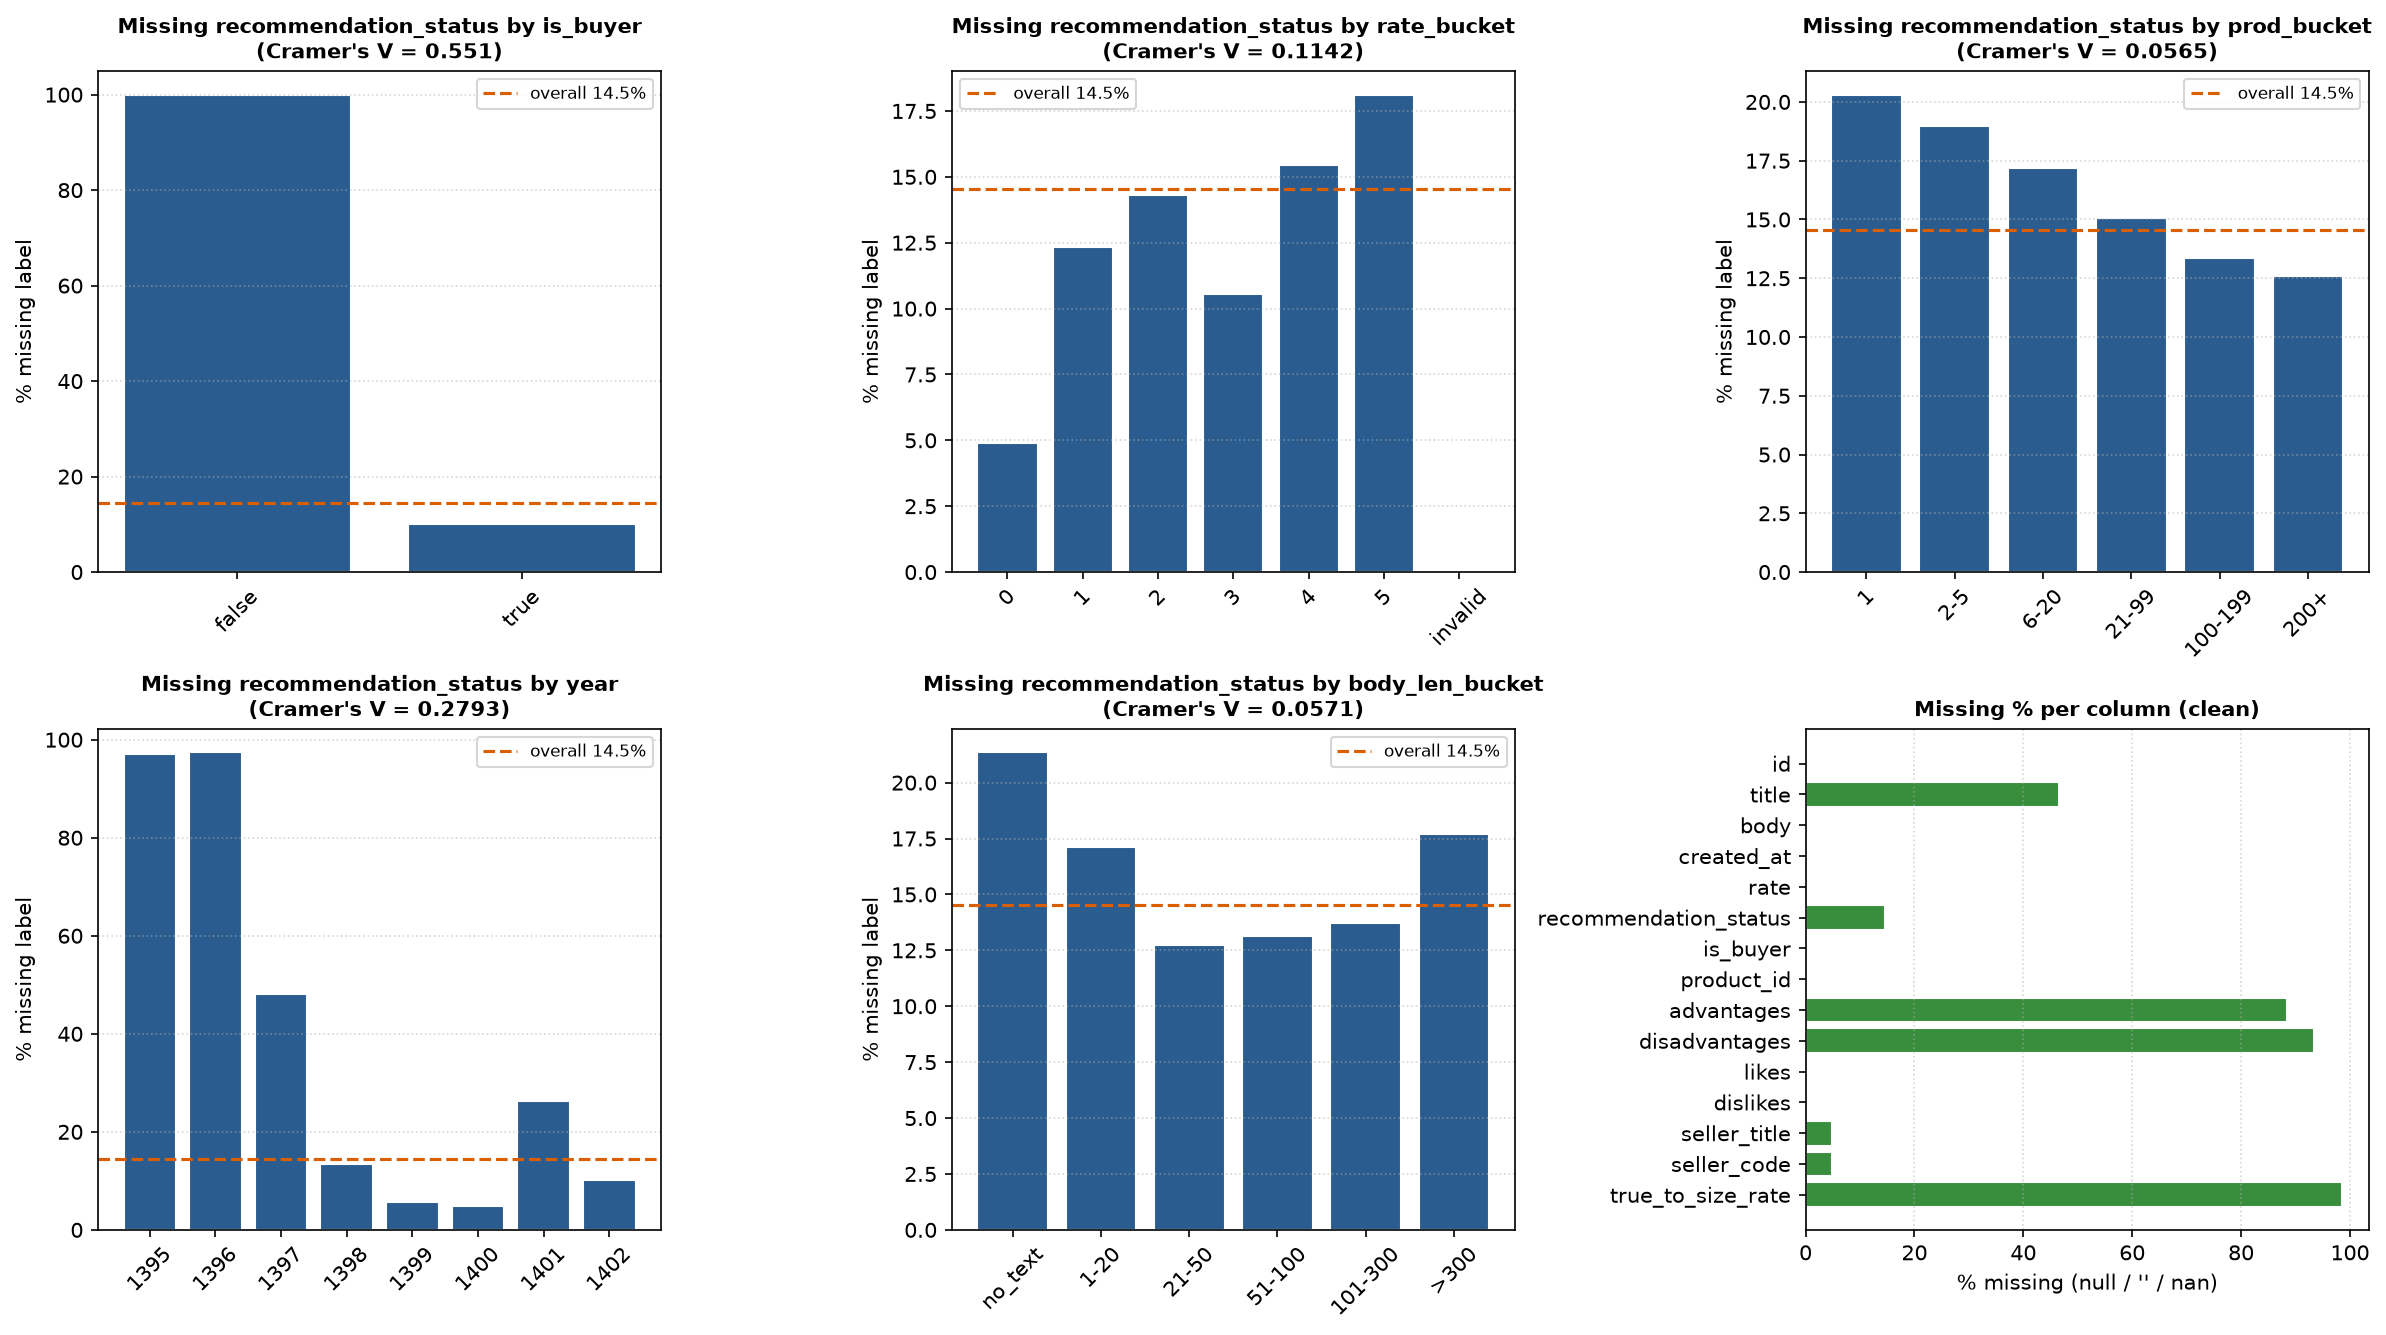

In [9]:
ov = m["recommendation_missing_overall"]
print(f"recommendation_status missing (clean): {ov['missing']:,} / {ov['total']:,} = {ov['pct']}%")
display(table([{"factor": f["factor"], "cramers_v": f["cramers_v"],
                "min_missing_%_(groups n>=1000)": f["missing_pct_min_group_n_ge_1000"],
                "max_missing_%_(groups n>=1000)": f["missing_pct_max_group_n_ge_1000"]} for f in m["factors"]]))
for f in m["factors"]:
    if f["factor"] in ("is_buyer", "year"):
        print("\nMissing label by", f["factor"])
        display(table(f["groups"]))
show_fig("A2_missing_patterns.png")

**Year × buyer check.** The jump in 2022 (Persian year 1401) could simply reflect non-buyers. The matrix below (recomputed from the clean Parquet if it exists locally) separates the two causes.

In [10]:
PQ = ROOT / "data" / "interim" / "digikala_clean.parquet"
if PQ.exists():
    lf = pl.scan_parquet(PQ)
    year = pl.col("created_at").str.extract(r"(\d{4})\s*$", 1).alias("year")
    miss = (pl.col("recommendation_status").is_null()
            | (pl.col("recommendation_status").str.to_lowercase() == "nan"))
    ybuy = (lf.group_by([year, "is_buyer"])
              .agg(pl.len().alias("n"), miss.sum().alias("missing"))
              .with_columns((pl.col("missing") / pl.col("n") * 100).round(2).alias("missing_pct"))
              .sort(["year", "is_buyer"]).collect(engine="streaming"))
    display(ybuy)
else:
    print("Clean Parquet not found locally (it is not in git). Values recorded from the script run:")
    print("buyers' missing label: 1400 -> 0.03%, 1401 -> 23.1% (479,358 / 2,075,542), 1402 -> 6.1%; "
          "non-buyers: 100% missing in every year.")

year,is_buyer,n,missing,missing_pct
str,bool,u32,u32,f64
"""1395""",false,3440,3440,100.0
"""1395""",true,121,18,14.88
"""1396""",false,6159,6159,100.0
"""1396""",true,183,18,9.84
"""1397""",false,7632,7632,100.0
"""1397""",true,9047,378,4.18
"""1398""",false,17813,17813,100.0
"""1398""",true,120782,827,0.68
"""1399""",false,38138,38138,100.0


**Conclusion A2.** Label missingness is **structural, not random (not MCAR)**: all 301,968 non-buyers have no label (100%), and among buyers the missing share jumps from 0.03% (1400) to 23.1% (1401) and falls to 6.1% (1402). *Hypothesis (not verified):* the "do you recommend?" question changed in 1401. Consequently the naturally unlabeled pool is not distributed like the labeled data, which is why the main semi-supervised comparison uses the artificial masking pool.

## A3. Target distributions
*Data: complete clean dataset. Bands: low 0 ≤ rate < 2.5, medium 2.5 ≤ rate < 4.0, high 4.0 ≤ rate ≤ 5.0; null/negative/over 5 = invalid.*

In [11]:
t = load("step_a3_targets.json")
print("recommendation_status (clean)")
display(table(t["recommendation_clean"]))
print("rating_band (clean)")
display(table(t["rating_band_clean"]))
print("Imbalance ratios (majority/minority, labeled classes):",
      t["imbalance_recommendation"], t["imbalance_band"])

recommendation_status (clean)


class,count,pct
str,str,str
"""recommended""","""4,160,637""","""67.621"""
"""no_idea""","""593,688""","""9.649"""
"""not_recommended""","""504,488""","""8.199"""
"""missing""","""894,045""","""14.531"""


rating_band (clean)


class,count,pct
str,str,str
"""low""","""1,091,781""","""17.744"""
"""medium""","""1,058,495""","""17.203"""
"""high""","""4,002,581""","""65.052"""
"""invalid""","""1""","""0"""


Imbalance ratios (majority/minority, labeled classes): {'majority': 'recommended', 'minority': 'not_recommended', 'ratio': 8.25} {'majority': 'high', 'minority': 'medium', 'ratio': 3.78}


In [12]:
rs = dict(t["rate_stats_valid_0_5"]); qs = rs.pop("quantiles")
display(kv({**rs, **{f"q_{k}": v for k, v in qs.items()}}))
print("rate=2500 (id 38631814) is the only value outside [0,5]; it is invalid for the band task. "
      "Stats above exclude it.")

metric,value
str,str
"""n""","""6,152,857"""
"""min""","""0"""
"""max""","""5"""
"""mean""","""3.648"""
"""median""","""4"""
"""std""","""1.567"""
"""n_unique""","""177"""
"""fractional_share_pct""","""3.706"""
"""q_p1""","""0"""


rate=2500 (id 38631814) is the only value outside [0,5]; it is invalid for the band task. Stats above exclude it.


rate vs recommendation (% of labeled rows; missing = % of all rows in the row group)


rate_group,n,recommended_pct_of_labeled,no_idea_pct_of_labeled,not_recommended_pct_of_labeled,missing_pct_of_row
str,str,str,str,str,str
"""0""","""529,020""","""84.52""","""4.08""","""11.4""","""4.79"""
"""1""","""327,346""","""4.24""","""7.43""","""88.34""","""12.48"""
"""2""","""197,936""","""11.63""","""32.61""","""55.76""","""15.42"""
"""3""","""958,268""","""50.12""","""42.79""","""7.09""","""10.76"""
"""4""","""1,514,849""","""92.98""","""6.55""","""0.47""","""15.68"""
"""5""","""2,397,383""","""98.93""","""0.75""","""0.32""","""18.12"""
"""fractional""","""228,055""","""70.52""","""15.99""","""13.5""","""9.81"""
"""invalid""","""1""","""100""","""0""","""0""","""0"""


rating_band vs recommendation


rating_band,n,recommended_pct_of_labeled,no_idea_pct_of_labeled,not_recommended_pct_of_labeled,missing_pct_of_row
str,str,str,str,str,str
"""low""","""1,091,781""","""46.71""","""10.51""","""42.78""","""9.22"""
"""medium""","""1,058,495""","""51.9""","""40.94""","""7.16""","""10.5"""
"""high""","""4,002,581""","""96.56""","""3.06""","""0.38""","""17.04"""
"""invalid""","""1""","""100""","""0""","""0""","""0"""


Share of rate=0 and fractional rate by Persian year


year,n,rate0,rate0_pct,fractional,fractional_pct
str,str,str,str,str,str
"""1395""","""3,561""","""64""","""1.8""","""1,957""","""54.96"""
"""1396""","""6,342""","""142""","""2.24""","""3,406""","""53.71"""
"""1397""","""16,679""","""1,992""","""11.94""","""6,881""","""41.26"""
"""1398""","""138,595""","""35,120""","""25.34""","""31,605""","""22.8"""
"""1399""","""684,176""","""140,555""","""20.54""","""84,435""","""12.34"""
"""1400""","""1,253,289""","""272,091""","""21.71""","""92,296""","""7.36"""
"""1401""","""2,165,222""","""72,693""","""3.36""","""7,097""","""0.33"""
"""1402""","""1,884,994""","""6,363""","""0.34""","""378""","""0.02"""


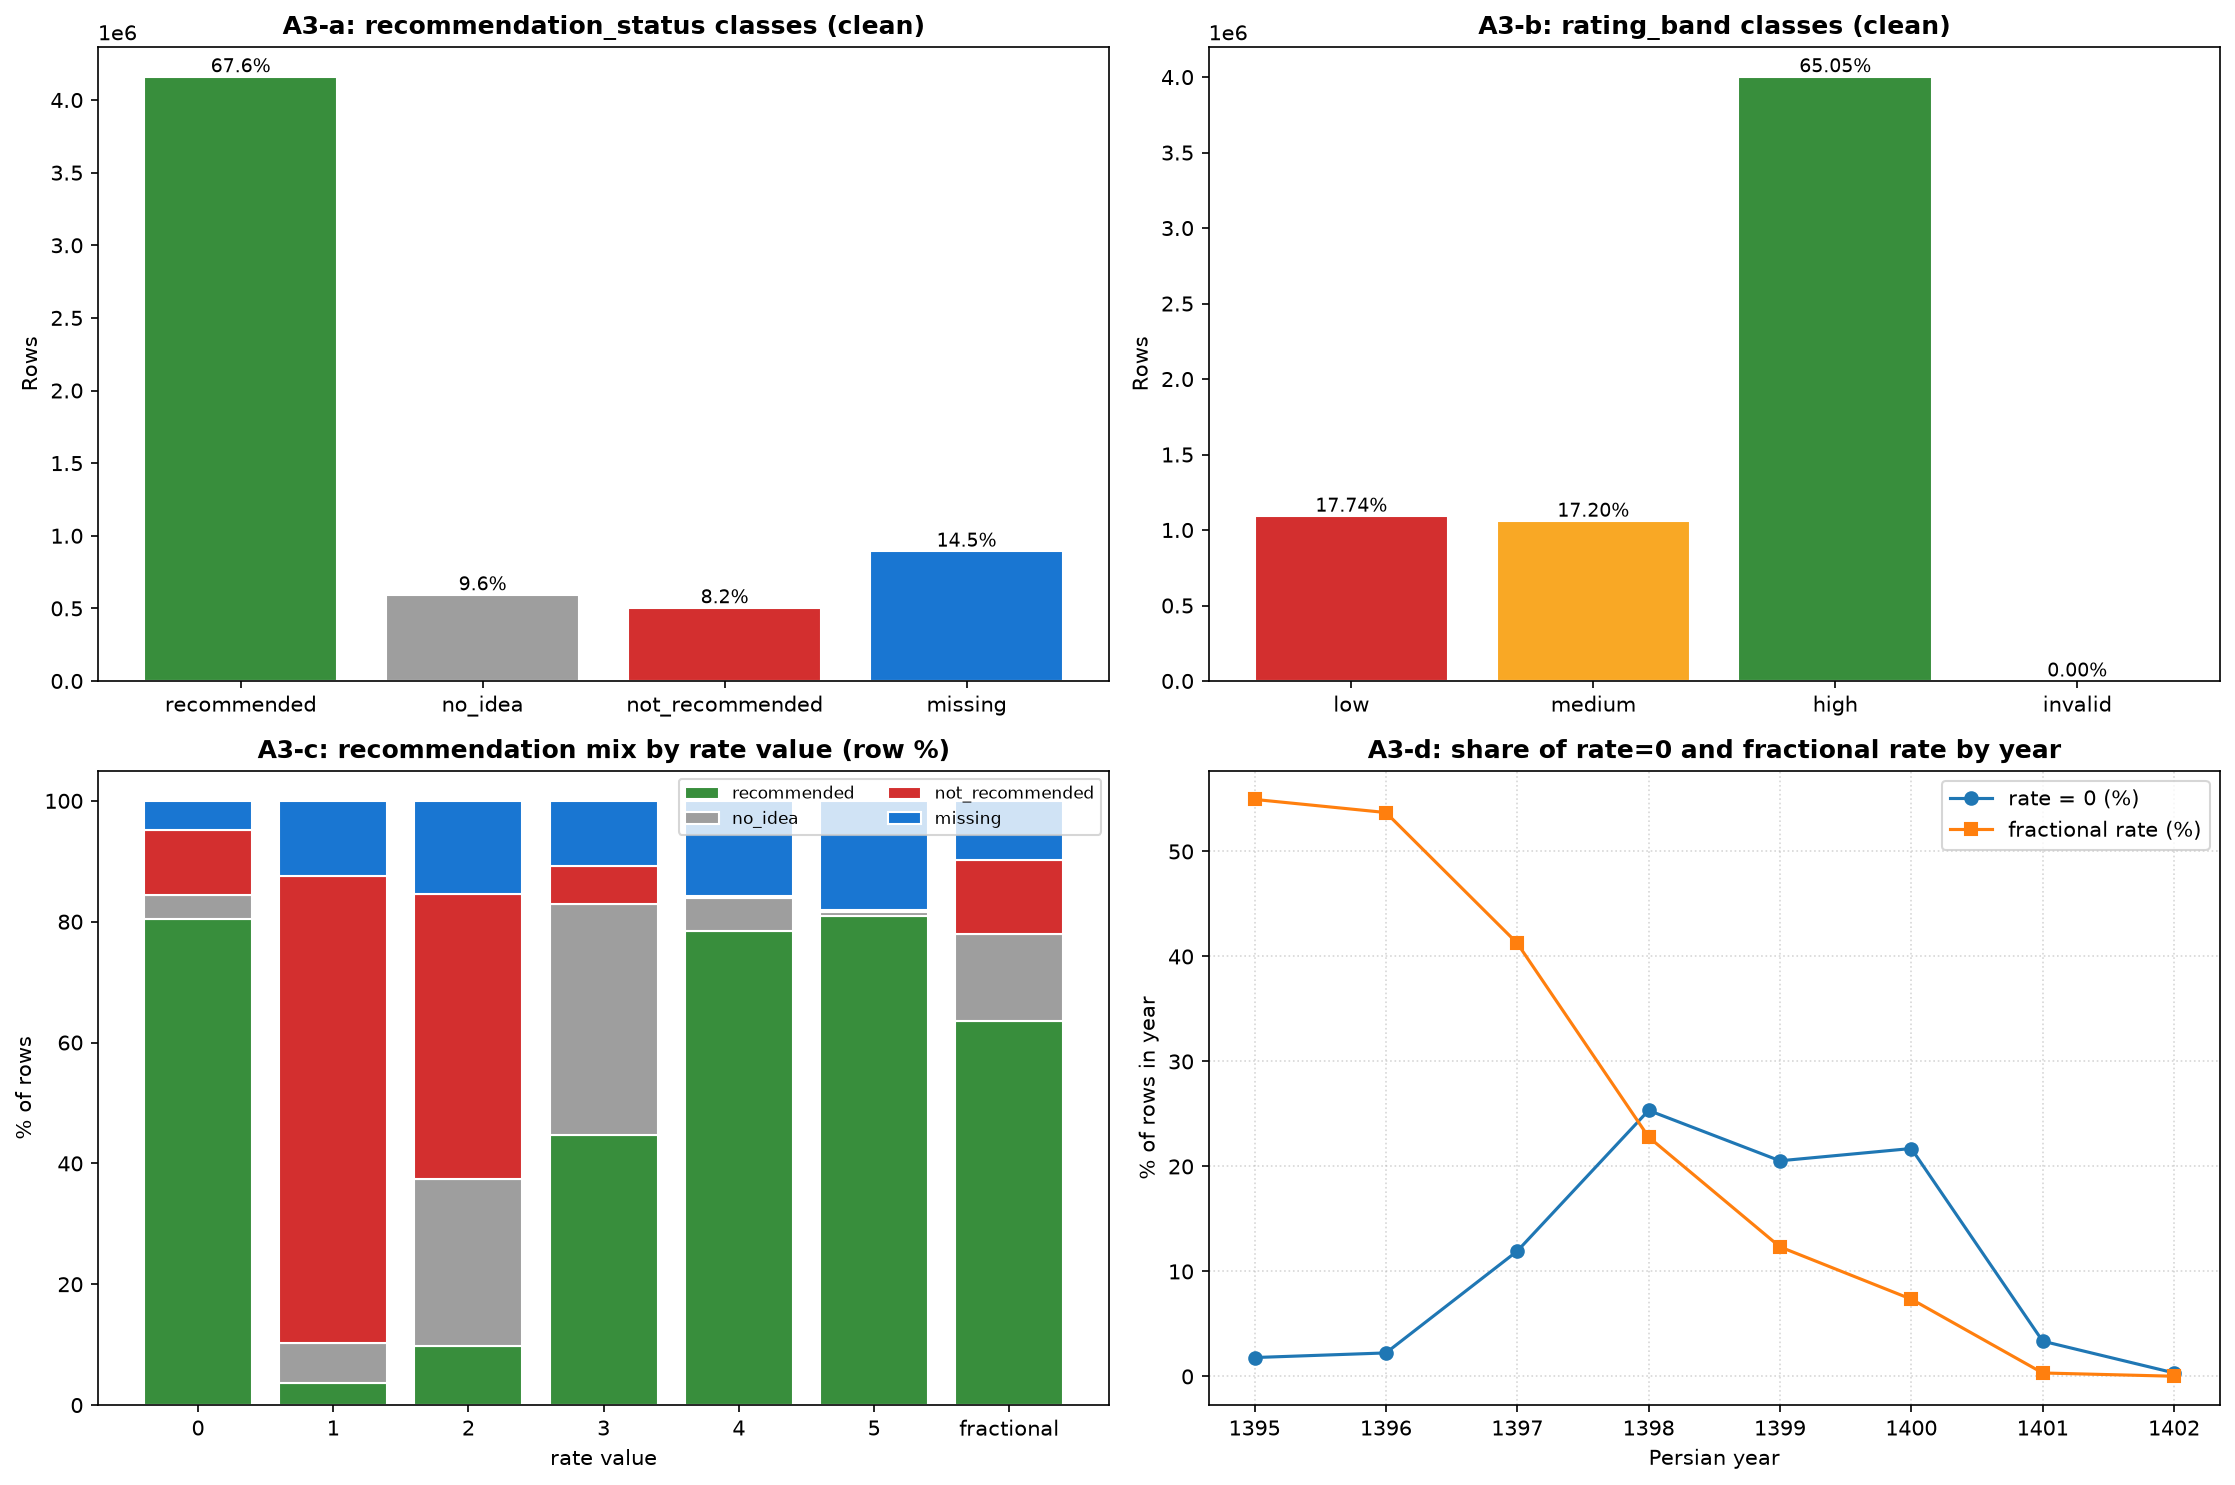

In [13]:
cols = ["rate_group", "n", "recommended_pct_of_labeled", "no_idea_pct_of_labeled",
        "not_recommended_pct_of_labeled", "missing_pct_of_row"]
print("rate vs recommendation (% of labeled rows; missing = % of all rows in the row group)")
display(table(t["rate_vs_recommendation"], cols))
cols_b = ["rating_band", "n", "recommended_pct_of_labeled", "no_idea_pct_of_labeled",
          "not_recommended_pct_of_labeled", "missing_pct_of_row"]
print("rating_band vs recommendation")
display(table(t["band_vs_recommendation"], cols_b))
print("Share of rate=0 and fractional rate by Persian year")
display(table(t["by_year"], ["year", "n", "rate0", "rate0_pct", "fractional", "fractional_pct"]))
show_fig("A3_target_distributions.png")

**Conclusion A3.** (1) Both targets are imbalanced (recommendation 8.25:1, band 3.78:1), so Macro-F1, per-class precision/recall/F1 and balanced accuracy matter more than accuracy. (2) `rate = 0` is suspicious: 529,020 rows (more than `rate = 1`), and among its labeled rows 84.5% are `recommended` versus 11.4% `not_recommended`, behaving like `rate = 5`, not like `rate = 1`. A manual sample of 30 `rate = 0` + `recommended` reviews (seed 2026) read mostly positive (about 27 of 30; observational evidence, not proof). So the `low` band is contaminated (only 42.8% of its labeled rows are `not_recommended`). (3) `rate = 0` and fractional rates change sharply with year (rate=0: ~20–25% in 1398–1400, 3.4% in 1401, 0.3% in 1402), which suggests a change in how ratings are recorded (*hypothesis*). (4) The raw numeric `rate` must never be a model input because it almost determines the band label (leakage).

## A4. Text-length analysis of `body`
*Data: characters and words — complete clean data (6,152,221 rows with real text). Tokens (`xlm-roberta-base`) — **bounded sample N=200,000, seed 2026**, random sample of rows with text.*

In [14]:
a4 = load("step_a4_text_length.json")
display(table([{"unit": "characters", **{k: a4["char_length"][k] for k in ("mean", "median", "p75", "p90", "p95", "p99", "p99.9", "max")}},
               {"unit": "words", **{k: a4["word_length"][k] for k in ("mean", "median", "p75", "p90", "p95", "p99", "p99.9", "max")}}]))
display(table([{"metric": k, "count": v, "pct": a4["short_long_pct"][k]} for k, v in a4["short_long_counts"].items()]))
print("Words by recommendation class"); display(table(a4["by_recommendation"]))
print("Words by rating band"); display(table(a4["by_rating_band"]))

unit,mean,median,p75,p90,p95,p99,p99.9,max
str,str,str,str,str,str,str,str,str
"""characters""","""48.02""","""29""","""57""","""106""","""151""","""295""","""649""","""4,000"""
"""words""","""10.12""","""6""","""12""","""22""","""32""","""62""","""136""","""911"""


metric,count,pct
str,str,str
"""chars_le_3""","""73,911""","""1.201"""
"""chars_le_10""","""828,938""","""13.474"""
"""words_eq_1""","""450,001""","""7.314"""
"""words_le_3""","""1,667,989""","""27.112"""
"""chars_gt_300""","""58,293""","""0.948"""
"""chars_gt_1000""","""1,595""","""0.026"""
"""words_gt_100""","""15,737""","""0.256"""
"""words_gt_200""","""1,865""","""0.03"""


Words by recommendation class


class,n,words_mean,words_median,words_p90,words_p99,chars_median,chars_p99
str,str,str,str,str,str,str,str
"""recommended""","""4,160,215""","""9.27""","""6""","""20""","""56""","""27""","""266"""
"""no_idea""","""593,645""","""12.4""","""8""","""27""","""70""","""37""","""333"""
"""not_recommended""","""504,452""","""15.22""","""10""","""33""","""80""","""48""","""380"""
"""missing""","""893,909""","""9.72""","""5""","""22""","""67""","""25""","""319"""


Words by rating band


class,n,words_mean,words_median,words_p90,words_p99,chars_median,chars_p99
str,str,str,str,str,str,str,str
"""low""","""1,091,645""","""12.58""","""8""","""28""","""70""","""38""","""334"""
"""medium""","""1,058,391""","""11.15""","""7""","""25""","""68""","""32""","""324"""
"""high""","""4,002,184""","""9.18""","""6""","""20""","""57""","""26""","""271"""


Tokenizer xlm-roberta-base | sample n=200,000 seed=2026 | tokens per word = 1.564


metric,value
str,str
"""mean""","""15.79"""
"""median""","""10"""
"""p90""","""32"""
"""p95""","""46"""
"""p99""","""86"""
"""p99.9""","""180"""
"""max""","""1,029"""


max_length,truncated_count,truncated_pct
str,str,str
"""64""","""4,421""","""2.211"""
"""128""","""632""","""0.316"""
"""256""","""81""","""0.04"""
"""512""","""7""","""0.003"""


Suggested max_length (smallest candidate truncating <= 2% of reviews): 128


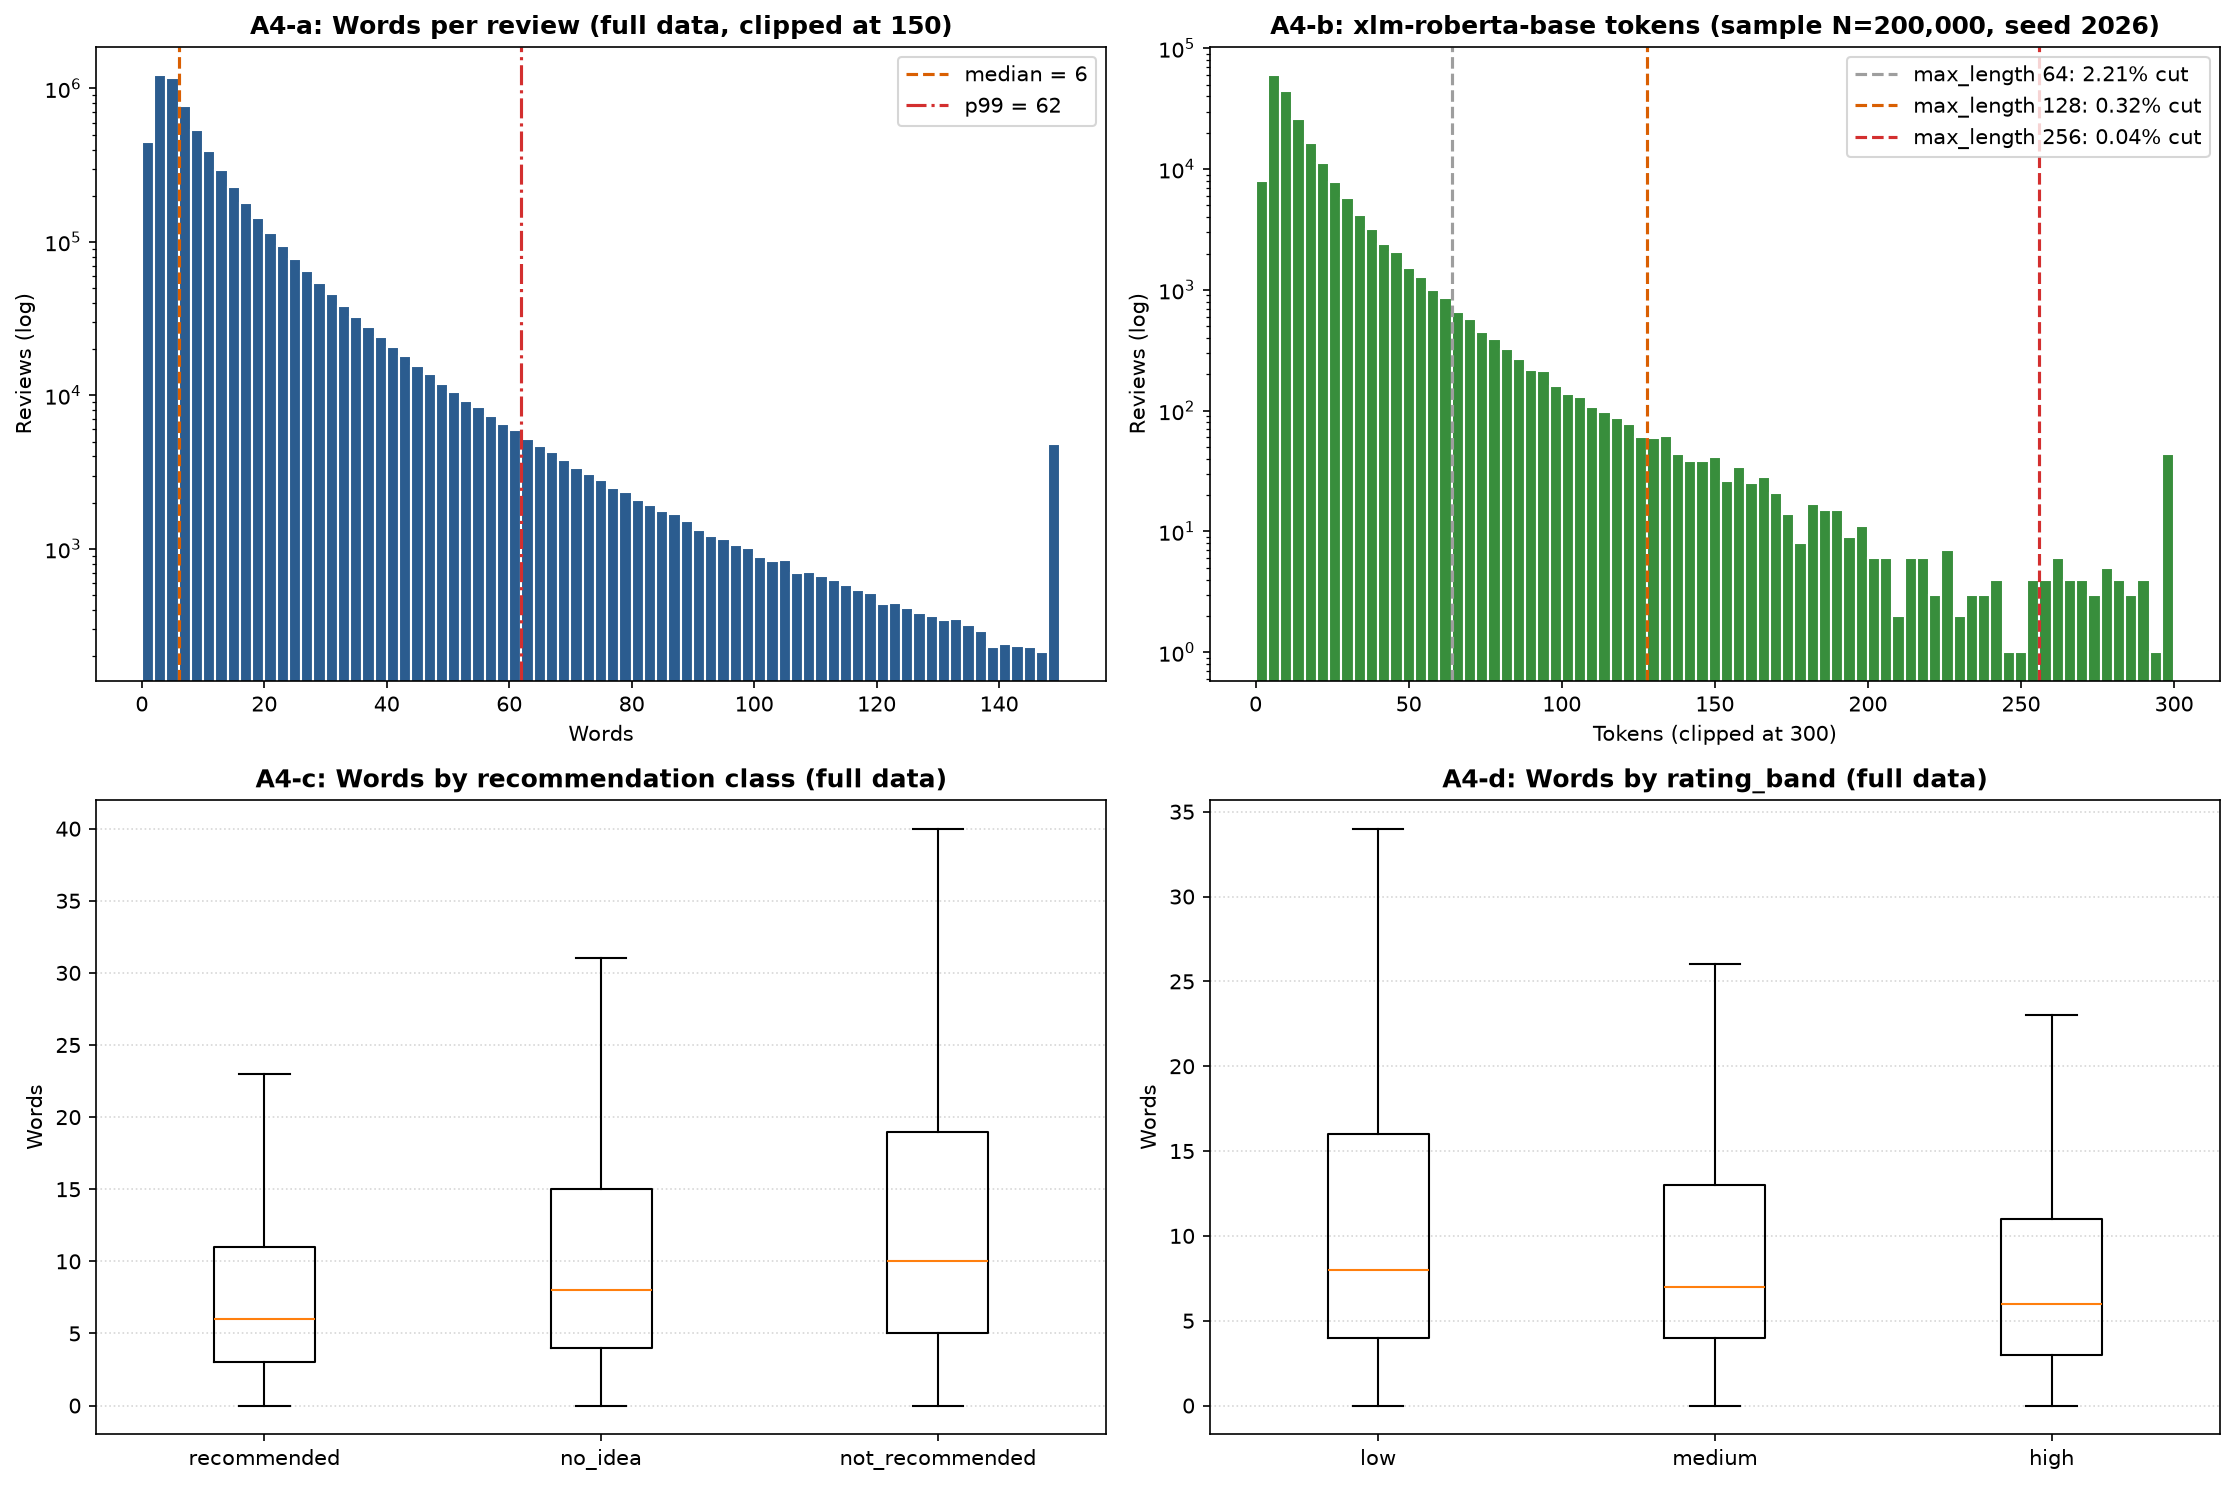

In [15]:
tk = a4.get("tokens")
if tk:
    ts = tk["token_stats"]
    print(f"Tokenizer {tk['tokenizer']} | sample n={tk['sample_n']:,} seed={tk['seed']} | tokens per word = {tk['tokens_per_word']}")
    display(kv(ts, ["mean", "median", "p90", "p95", "p99", "p99.9", "max"]))
    display(table([{"max_length": k, **v} for k, v in tk["truncation"].items()]))
    print("Suggested max_length (smallest candidate truncating <= 2% of reviews):", a4["suggested_max_length"])
else:
    print("Token statistics are missing (tokenizer was unavailable when step_a4.py ran).")
show_fig("A4_text_length.png")

**Conclusion A4.** Reviews are very short: median 6 words (29 characters), p99 = 62 words; 27.1% have at most 3 words and 7.3% are a single word. With `xlm-roberta-base` the median is 10 tokens and `max_length = 128` truncates only 0.32% of reviews (64 would cut 2.2%). **Proposed decision:** `max_length = 128` (the "≤ 2% truncation" rule is our own convention) with dynamic padding. `not_recommended` and `low` reviews are longer than `recommended`/`high` (mean 15.2 vs 9.3 words), so truncation hurts minority classes slightly more; this is correlation, not cause. Very short reviews are inherently ambiguous, which caps achievable accuracy.

## A5. Repetition, label conflicts, and concentration
*Data: complete clean dataset, comparisons on **normalized text** (`normalize_text_minimal`). The leakage simulation is an illustration using a hash 70/15/15 split (seed 2026), not the official Part B split.*

In [16]:
a5 = load("step_a5_repetition_concentration.json")
dup = a5["duplicate_bodies"]
display(table([{"basis": k, **dup[k]} for k in ("raw", "normalized")],
              ["basis", "unique_bodies", "duplicated_bodies", "rows_in_duplicated_bodies",
               "rows_in_duplicated_bodies_pct", "extra_rows_beyond_first"]))
print("Unique bodies merged by normalization:", f"{dup['unique_bodies_merged_by_normalization']:,}")
print("Share of rows whose text appears more than once, by word count")
display(table(a5["duplicate_share_by_word_count"], ["wb", "n", "dup_rows", "dup_pct"]))

basis,unique_bodies,duplicated_bodies,rows_in_duplicated_bodies,rows_in_duplicated_bodies_pct,extra_rows_beyond_first
str,str,str,str,str,str
"""raw""","""4,135,920""","""195,604""","""2,211,905""","""35.953""","""None"""
"""normalized""","""4,017,621""","""191,384""","""2,325,984""","""37.807""","""2,134,600"""


Unique bodies merged by normalization: 118,299
Share of rows whose text appears more than once, by word count


wb,n,dup_rows,dup_pct
str,str,str,str
"""1""","""450,206""","""441,879""","""98.15"""
"""2""","""565,612""","""524,157""","""92.671"""
"""3""","""652,171""","""522,933""","""80.183"""
"""4-5""","""1,173,145""","""630,238""","""53.722"""
"""6-10""","""1,521,563""","""165,841""","""10.899"""
"""11-20""","""1,085,368""","""27,095""","""2.496"""
"""21+""","""704,156""","""13,841""","""1.966"""


In [17]:
rows = []
for seg in ("all", "short", "long"):
    for task in ("recommendation", "rating_band", "rating_band_excluding_rate0"):
        c = a5["label_conflicts"][seg][task]
        rows.append({"segment": seg, "task": task, **c})
print("Identical normalized text with conflicting labels (short = at most 3 words)")
display(table(rows))
print("Repeated texts appearing in more than one product:", a5["duplicated_texts_across_products"])

Identical normalized text with conflicting labels (short = at most 3 words)


segment,task,groups_with_2plus_labeled_rows,conflicting_groups,conflict_pct_of_groups,rows_in_conflicting_groups
str,str,str,str,str,str
"""all""","""recommendation""","""168,170""","""31,453""","""18.703""","""1,625,827"""
"""all""","""rating_band""","""191,384""","""81,482""","""42.575""","""1,995,464"""
"""all""","""rating_band_excluding_rate0""","""174,859""","""59,646""","""34.111""","""1,888,763"""
"""short""","""recommendation""","""48,494""","""13,741""","""28.335""","""1,260,137"""
"""short""","""rating_band""","""55,110""","""30,070""","""54.564""","""1,409,658"""
"""short""","""rating_band_excluding_rate0""","""51,555""","""23,326""","""45.245""","""1,372,399"""
"""long""","""recommendation""","""119,676""","""17,712""","""14.8""","""365,690"""
"""long""","""rating_band""","""136,274""","""51,412""","""37.727""","""585,806"""
"""long""","""rating_band_excluding_rate0""","""123,304""","""36,320""","""29.456""","""516,364"""


Repeated texts appearing in more than one product: {'duplicated_groups_spanning_multiple_products': 190834, 'pct_of_duplicated_groups': 99.713, 'rows_in_those_groups': 2324880}


metric,products,sellers
str,str,str
"""n_entities""","""331,592""","""29,211"""
"""gini""","""0.765""","""0.893"""
"""top_1pct_share_of_reviews""","""10.827""","""41.685"""
"""top_5pct_share_of_reviews""","""48.06""","""71.789"""
"""top_10pct_share_of_reviews""","""67.114""","""84.352"""
"""top_20pct_share_of_reviews""","""82.42""","""93.45"""
"""top_100_share_of_reviews""","""0.341""","""26.266"""


split,test_rows,test_rows_product_in_train_pct,test_rows_text_in_train_pct,test_long_rows_text_in_train_pct
str,str,str,str,str
"""row_level_random""","""923,456""","""97.888""","""36.634""","""17.501"""
"""product_grouped""","""930,199""","""0""","""36.605""","""17.408"""


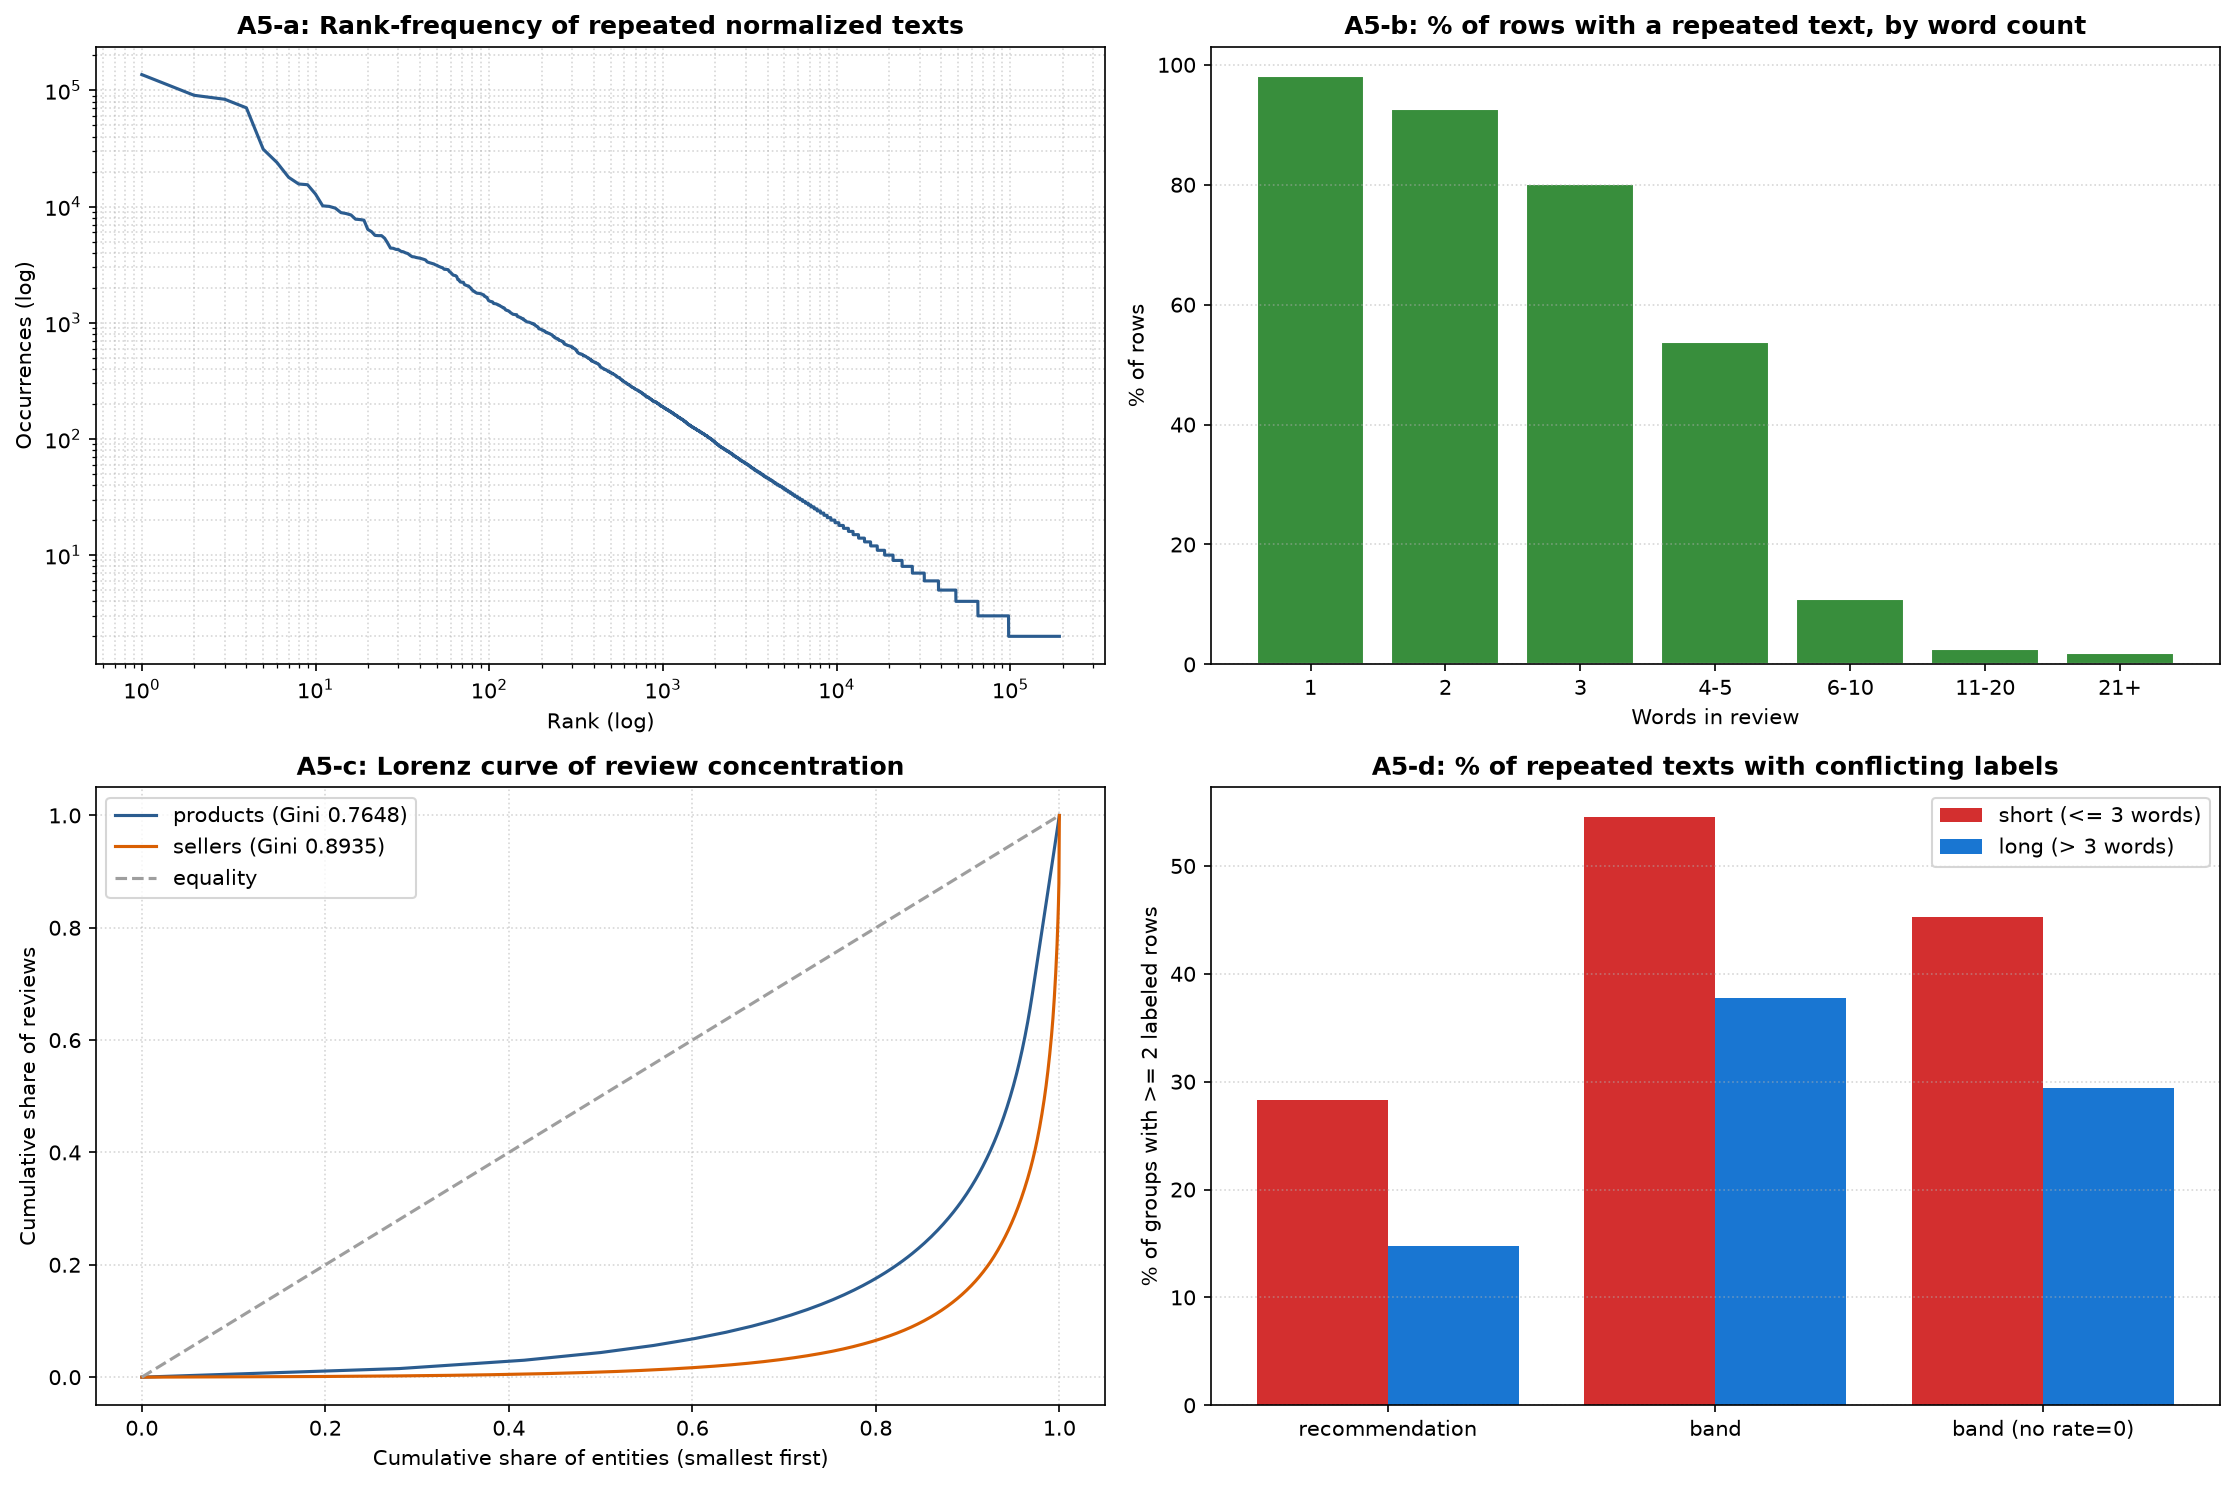

In [18]:
cp, cs = a5["concentration"]["products"], a5["concentration"]["sellers"]
keys = ["n_entities", "gini", "top_1pct_share_of_reviews", "top_5pct_share_of_reviews",
        "top_10pct_share_of_reviews", "top_20pct_share_of_reviews", "top_100_share_of_reviews"]
display(table([{"metric": k, "products": cp.get(k), "sellers": cs.get(k)} for k in keys]))
lk = a5["leakage_simulation"]
display(table([{"split": k, **{kk: vv for kk, vv in lk[k].items()}} for k in ("row_level_random", "product_grouped")],
              ["split", "test_rows", "test_rows_product_in_train_pct", "test_rows_text_in_train_pct",
               "test_long_rows_text_in_train_pct"]))
show_fig("A5_repetition_concentration.png")

**Conclusion A5.** (1) 37.8% of rows carry a text that occurs more than once, and 98% of one-word reviews are repeats; normalization merged 118,299 distinct raw strings. (2) For identical texts, labels often disagree: 18.7% of repeated texts conflict on recommendation and 42.6% on band (34.1% when `rate = 0` rows are excluded). Much of this is inherent ambiguity of short generic texts rather than annotation error, so it is an **accuracy ceiling** and an error-analysis category. (3) Reviews are concentrated in a few products (Gini 0.76; note the scraper caps each product at about 200 reviews, so this understates real concentration) and especially in a few sellers (top 1% of sellers = 41.7% of reviews). (4) A row-level split would put 97.9% of test rows' products in train; a product-grouped split puts 0%. **But** 36.6% of test rows have an identical text in train under *both* splits, because repeated texts spread across products (99.7%). **Proposed decision:** product-grouped split is required but not sufficient; we additionally report metrics on a subset whose text does not occur in train.

## A6. Vocabulary-level analysis (optional extension)
*Data: **bounded sample N=1,000,000, seed 2026** (random rows with text). Counts are document frequencies (a word counts once per review).*

In [19]:
a6 = load("step_a6_vocabulary.json")
display(kv({k: v for k, v in a6["vocabulary"].items() if k != "coverage_of_token_occurrences_pct"}))
print("Token coverage by top-k words (%):", a6["vocabulary"]["coverage_of_token_occurrences_pct"])
print("Top 15 words"); display(table(a6["top_words"][:15], ["rank", "word", "df", "pct_reviews"]))
print("Top 15 bigrams"); display(table(a6["top_bigrams"][:15], ["rank", "bigram", "df", "pct_reviews"]))

metric,value
str,str
"""sample_reviews""","""1,000,000"""
"""total_tokens""","""10,118,400"""
"""unique_words""","""120,780"""
"""words_df_ge_5""","""26,405"""
"""words_df_ge_MIN_DF""","""3,070"""
"""hapax_words""","""68,371"""
"""hapax_share_of_vocab_pct""","""56.61"""


Token coverage by top-k words (%): {'top_50': 41.07, 'top_100': 51.37, 'top_1000': 82.59, 'top_5000': 94.5, 'top_20000': 98.27}
Top 15 words


rank,word,df,pct_reviews
str,str,str,str
"""1""","""و""","""308,294""","""30.829"""
"""2""","""بود""","""195,123""","""19.512"""
"""3""","""خیلی""","""190,163""","""19.016"""
"""4""","""خوب""","""172,893""","""17.289"""
"""5""","""به""","""148,095""","""14.809"""
"""6""","""خوبه""","""147,924""","""14.792"""
"""7""","""از""","""127,880""","""12.788"""
"""8""","""عالی""","""122,662""","""12.266"""
"""9""","""من""","""113,962""","""11.396"""


Top 15 bigrams


rank,bigram,df,pct_reviews
str,str,str,str
"""1""","""خوب بود""","""70,903""","""7.09"""
"""2""","""نسبت به""","""37,132""","""3.713"""
"""3""","""عالی بود""","""29,910""","""2.991"""
"""4""","""خوب و""","""28,299""","""2.83"""
"""5""","""خوبی داره""","""27,116""","""2.712"""
"""6""","""خیلی خوبه""","""26,970""","""2.697"""
"""7""","""خیلی خوب""","""24,143""","""2.414"""
"""8""","""دیجی کالا""","""21,221""","""2.122"""
"""9""","""در کل""","""19,824""","""1.982"""


In [20]:
for c, rows in a6["class_terms"]["recommendation"].items():
    print("Terms most distinctive of recommendation class:", c)
    display(table(rows[:10], ["word", "log_odds", "pct_in_group", "pct_in_rest"]))
lv = a6["labeled_vs_natural"]
print({k: lv[k] for k in ("jaccard_top5000_words", "oov_rate_natural_vs_labeled_vocab_pct",
                           "oov_rate_labeled_vs_natural_vocab_pct")})
print("More frequent in naturally unlabeled reviews"); display(table(lv["terms_more_in_natural_unlabeled"][:10], ["word", "log_odds", "pct_in_group", "pct_in_rest"]))
print("More frequent in labeled reviews"); display(table(lv["terms_more_in_labeled"][:10], ["word", "log_odds", "pct_in_group", "pct_in_rest"]))

Terms most distinctive of recommendation class: recommended


word,log_odds,pct_in_group,pct_in_rest
str,str,str,str
"""دوسشون""","""1.462""","""0.029""","""0.006"""
"""عالیییییییییی""","""1.337""","""0.032""","""0.008"""
"""گوگولی""","""1.248""","""0.084""","""0.024"""
"""خواندنی""","""1.191""","""0.076""","""0.023"""
"""عالیییییییی""","""1.167""","""0.043""","""0.013"""
"""اموزنده""","""1.153""","""0.033""","""0.01"""
"""ومناسب""","""1.13""","""0.039""","""0.012"""
"""مندان""","""1.129""","""0.035""","""0.011"""
"""عالین""","""1.12""","""0.109""","""0.035"""


Terms most distinctive of recommendation class: no_idea


word,log_odds,pct_in_group,pct_in_rest
str,str,str,str
"""نپسندیدم""","""2.121""","""0.142""","""0.017"""
"""تعریفی""","""1.935""","""0.178""","""0.026"""
"""نیومد""","""1.893""","""0.904""","""0.137"""
"""معمولیه""","""1.892""","""2.005""","""0.307"""
"""معمولی""","""1.856""","""6.726""","""1.115"""
"""راستش""","""1.821""","""0.19""","""0.031"""
"""آنچنان""","""1.782""","""0.091""","""0.015"""
"""چندانی""","""1.754""","""0.204""","""0.035"""
"""آنچنانی""","""1.744""","""0.11""","""0.019"""


Terms most distinctive of recommendation class: not_recommended


word,log_odds,pct_in_group,pct_in_rest
str,str,str,str
"""پولتونو""","""4.087""","""0.404""","""0.007"""
"""آشغاله""","""4.041""","""0.213""","""0.004"""
"""مزخرف""","""4.035""","""0.371""","""0.007"""
"""پولتون""","""3.932""","""0.56""","""0.011"""
"""نریزید""","""3.795""","""0.282""","""0.006"""
"""متاسفم""","""3.738""","""1.228""","""0.03"""
"""نخور""","""3.724""","""0.989""","""0.024"""
"""آشغال""","""3.709""","""0.717""","""0.018"""
"""افتضاح""","""3.686""","""3.205""","""0.083"""


{'jaccard_top5000_words': 0.8202, 'oov_rate_natural_vs_labeled_vocab_pct': 2.028, 'oov_rate_labeled_vs_natural_vocab_pct': 3.705}
More frequent in naturally unlabeled reviews


word,log_odds,pct_in_group,pct_in_rest
str,str,str,str
"""موجودش""","""3.061""","""0.193""","""0.009"""
"""نخریدم""","""2.981""","""0.231""","""0.012"""
"""لطفا""","""1.587""","""1.161""","""0.24"""
"""موجود""","""1.521""","""1.063""","""0.234"""
"""نگرفتم""","""1.212""","""0.096""","""0.029"""
"""بگذارید""","""1.151""","""0.052""","""0.017"""
"""خواهش""","""0.977""","""0.055""","""0.021"""
"""عطرهای""","""0.918""","""0.05""","""0.02"""
"""بیارید""","""0.911""","""0.051""","""0.021"""


More frequent in labeled reviews


word,log_odds,pct_in_group,pct_in_rest
str,str,str,str
"""عکسشو""","""1.372""","""0.061""","""0.015"""
"""میذارم""","""1.326""","""0.066""","""0.017"""
"""قلمو""","""1.272""","""0.026""","""0.007"""
"""تولیدش""","""1.236""","""0.022""","""0.006"""
"""مرجوعش""","""1.061""","""0.124""","""0.043"""
"""گذاشتم""","""1.052""","""0.233""","""0.081"""
"""سوتین""","""0.956""","""0.028""","""0.01"""
"""مقوا""","""0.955""","""0.035""","""0.013"""
"""گلاسه""","""0.918""","""0.04""","""0.016"""


Negation / contrast words (% of reviews)


word,pct_overall,pct_recommended,pct_no_idea,pct_not_recommended,pct_missing
str,str,str,str,str,str
"""نه""","""0.833""","""0.555""","""1.831""","""2.181""","""0.7"""
"""نیست""","""5.155""","""3.243""","""13.584""","""12.897""","""4.069"""
"""نبود""","""2.406""","""1.082""","""7.589""","""8.019""","""1.942"""
"""نداره""","""2.605""","""1.641""","""5.109""","""8.158""","""2.28"""
"""ندارد""","""0.319""","""0.138""","""0.581""","""1.541""","""0.296"""
"""نمی""","""0.966""","""0.523""","""1.861""","""3.865""","""0.79"""
"""نشد""","""0.224""","""0.126""","""0.461""","""0.817""","""0.184"""
"""بد""","""2.664""","""1.591""","""7.94""","""5.928""","""2.304"""
"""ولی""","""9.206""","""7.784""","""20.135""","""10.688""","""7.721"""


Stoplist risk: {'top50_contains_negation_words': ['ولی', 'نیست', 'اما'], 'top100_contains_negation_words': ['ولی', 'نیست', 'اما', 'بد', 'نداره', 'نبود'], 'top50_token_coverage_pct': 41.07, 'note': 'A frequency-based stoplist would delete these words; stopword removal must stay an experiment.'}


group,elongation,latin_letters,digits,emoji
str,str,str,str,str
"""recommended""","""3.843""","""0.536""","""3.947""","""0.813"""
"""no_idea""","""3.605""","""0.927""","""6.507""","""0.556"""
"""not_recommended""","""5.629""","""1.297""","""9.267""","""0.71"""
"""missing""","""3.879""","""0.658""","""4.547""","""0.707"""


Any negation/contrast word by class (%): {'recommended': 15.264, 'no_idea': 47.549, 'not_recommended': 50.295, 'missing': 18.261}


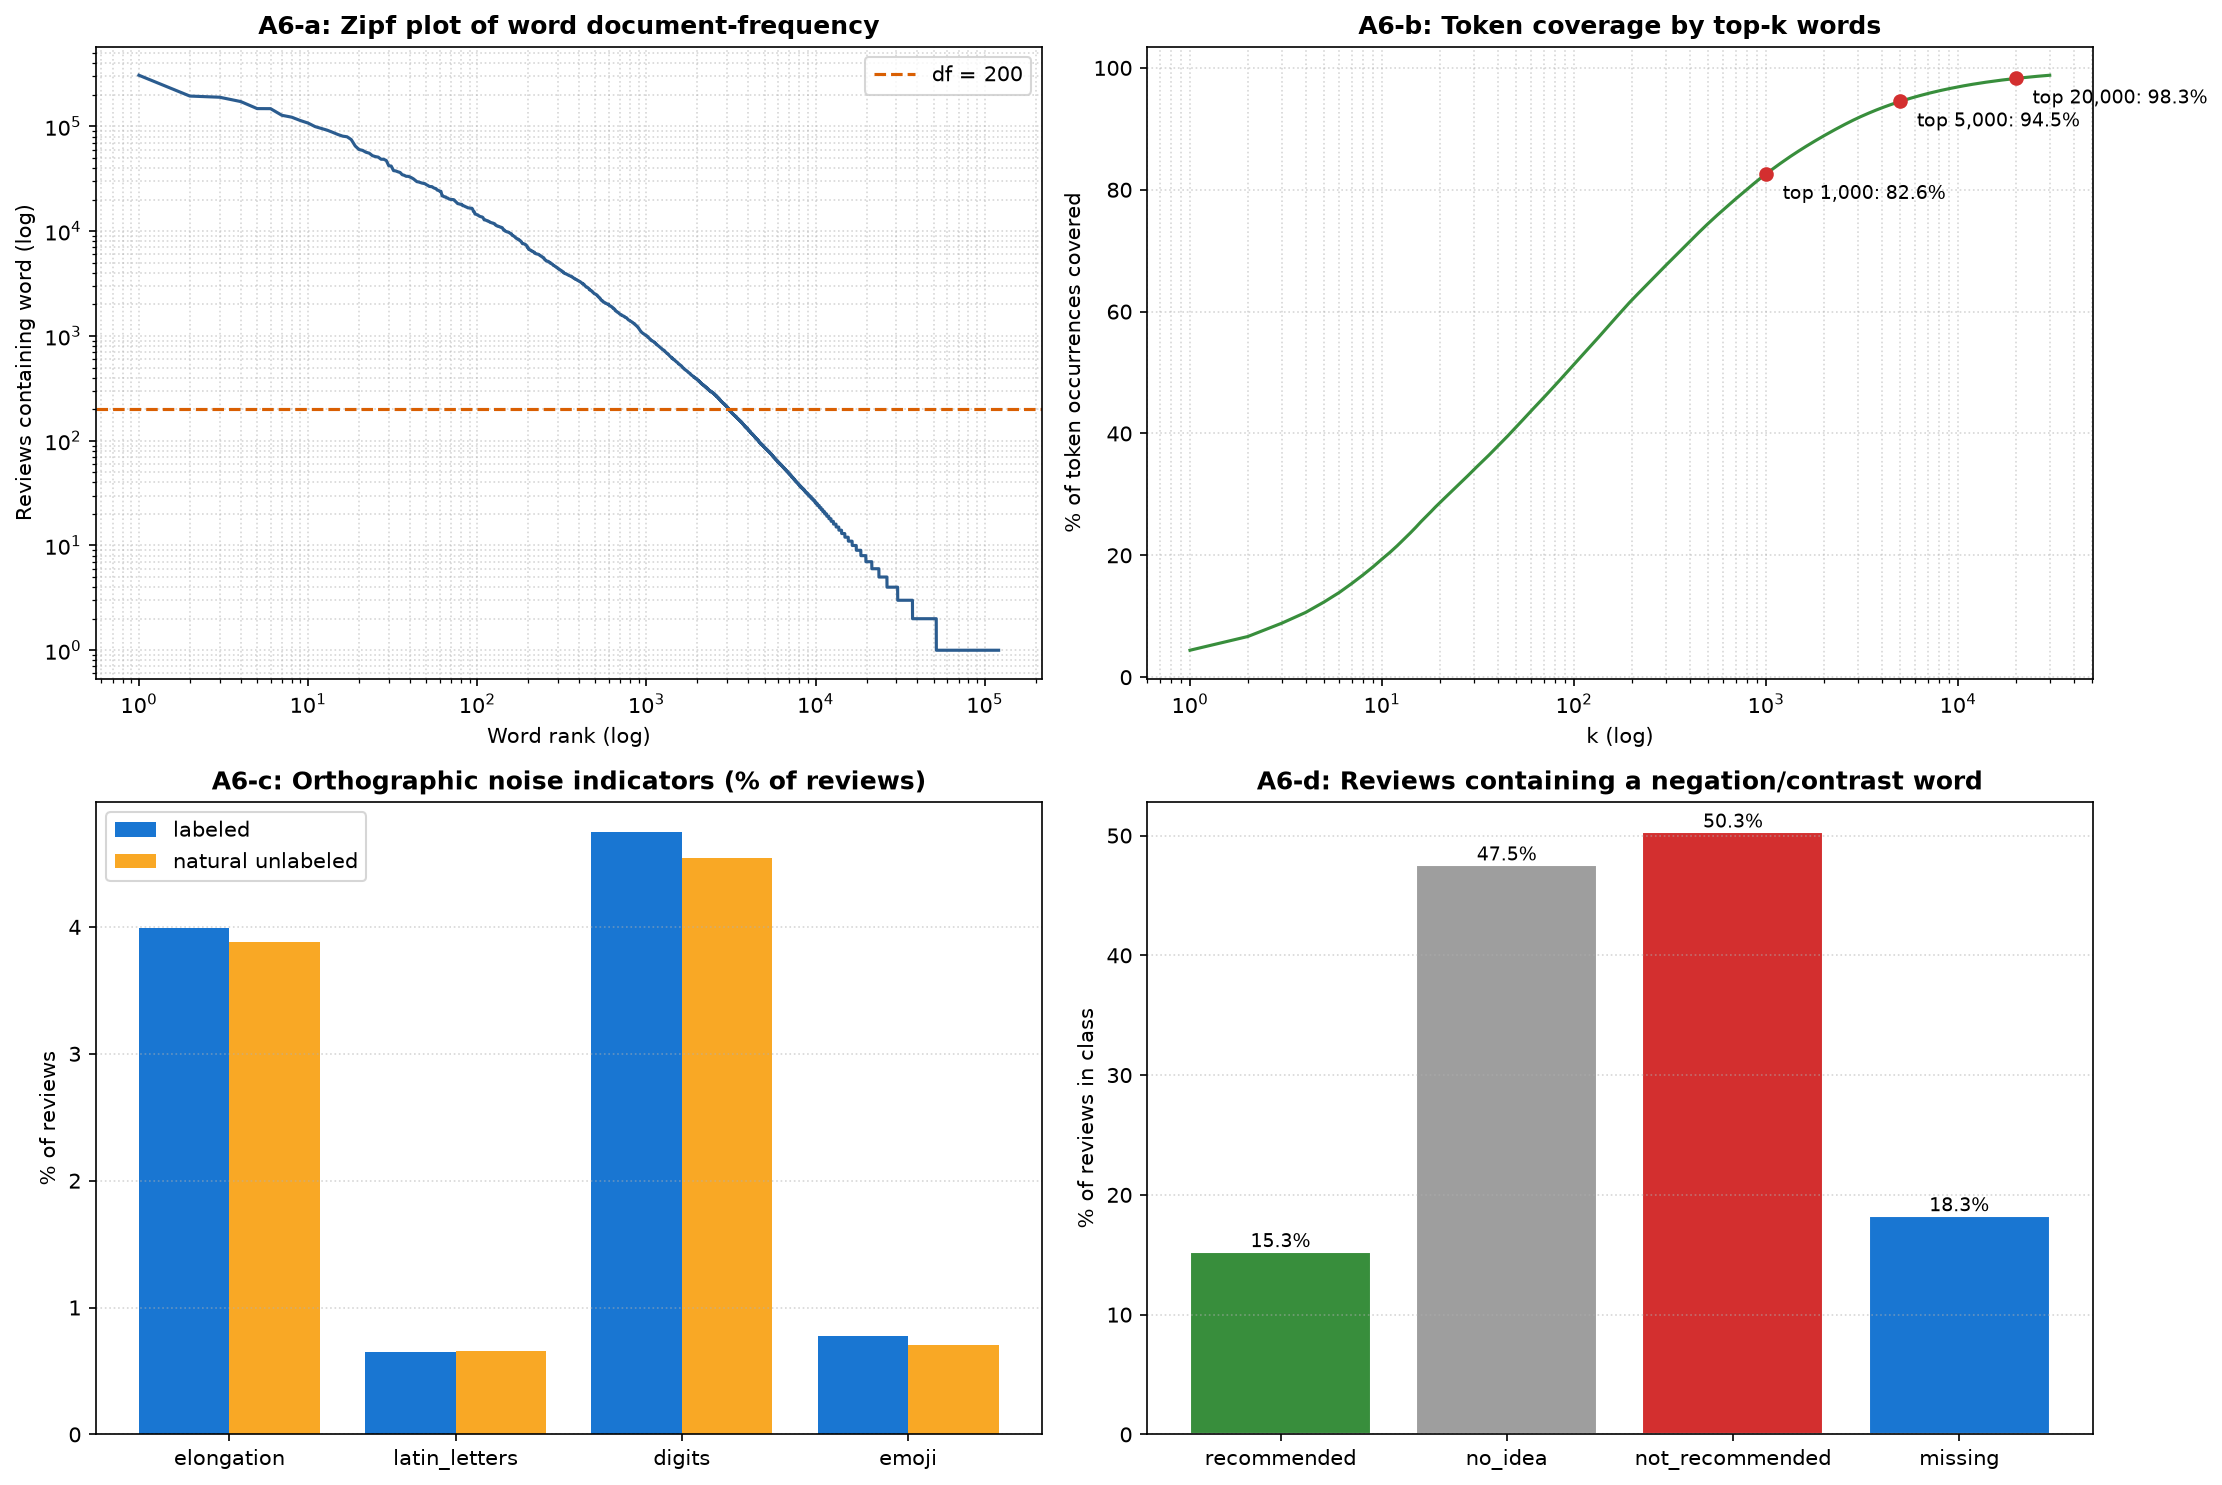

In [21]:
print("Negation / contrast words (% of reviews)")
display(table(a6["negation_words"]))
print("Stoplist risk:", a6["stoplist_risk"])
n = a6["noise_indicators_pct"]
display(table([{"group": g, **v} for g, v in n["by_recommendation_class"].items()]))
print("Any negation/contrast word by class (%):", n["any_negation_word_by_class"])
show_fig("A6_vocabulary.png")

**Conclusion A6.** (1) The vocabulary has a long noisy tail: 120,780 distinct words in the sample, 56.6% appear exactly once, and elongations such as «عالییییی» and glued forms such as «ومناسب» are visible among the "distinctive" terms. Subword tokenization (`xlm-roberta-base`) fits this better than a closed word vocabulary. (2) Negation/contrast cues are strong: at least one cue word appears in 50.3% of `not_recommended` and 47.5% of `no_idea` reviews versus 15.3% of `recommended`; 3 of the 50 most frequent words are such cues, so a frequency-based stoplist would delete signal. **Proposed decision:** no stopword removal by default; it is run only as a documented experiment. (3) `not_recommended` terms are unambiguous warnings («افتضاح»، «مزخرف»، «نخرید»، «پولتونو»), while `no_idea` and `medium` terms are hedges («معمولی»، «تعریفی»، «چندان»). The bigram «بد نیست» ("not bad", 1.16% of reviews) is positive even though it contains «بد»: a bag-of-words baseline cannot resolve this, whereas a contextual model can. (4) Naturally unlabeled reviews overlap strongly in vocabulary with labeled ones (Jaccard of the top 5000 words = 0.82); the words over-represented there are questions and requests («موجود»، «لطفا»، «بیارید»، «اطلاع»), consistent with the non-buyer origin found in A2. (5) Digits (9.3%), elongation (5.6%) and Latin letters (1.3%) are more frequent in `not_recommended` than in `recommended` (3.9%, 3.8%, 0.5%); we propose normalizing digits rather than deleting them.

## A7. Conclusions and links to modeling decisions

| # | Finding (evidence) | Proposed modeling decision |
|---|---|---|
| 1 | Label missingness is structural: non-buyers 100% unlabeled; buyers 0.03% → 23.1% → 6.1% across 1400–1402 (A2) | The main semi-supervised comparison uses the artificial masking pool; natural unlabeled rows are an optional extension. Rows with a missing target stay in their product's split and only the head with a valid target uses them. |
| 2 | Imbalance: recommendation 8.25:1, band 3.78:1 (A3) | Macro-F1, per-class P/R/F1, balanced accuracy, confusion matrices, ordinal distance error; class weights fitted on train only. |
| 3 | `rate = 0` behaves like a high rating (84.5% recommended among labeled) and contaminates `low`; `rate = 2500` is invalid (A3) | Keep the official bands. Add an ablation that masks the band loss for `rate = 0` rows and report band Macro-F1 with and without them. Never use `rate` as a feature. |
| 4 | Reviews are short: median 6 words / 10 tokens; 128 tokens truncates 0.32% (A4) | `max_length = 128`, dynamic padding, length bucketing; short ambiguous texts become an error-analysis category. |
| 5 | 37.8% of rows have repeated text; identical texts conflict in labels (18.7% recommendation, 42.6% band) (A5) | Treat conflicts as an accuracy ceiling; report extra metrics on the subset whose text is not in train; label-noise-robust training in the ablation table (label smoothing, soft ordinal targets, agreement weighting). |
| 6 | Reviews concentrate in products and sellers; row-level split leaks products (97.9%) but a grouped split removes it (0%); text duplicates still leak (36.6%) (A5) | Product-grouped 70/15/15 split from the shared seed (`SPLIT_SEED = 2026`); seller and product ids are never features; re-measure text leakage on the official split. |
| 7 | Noisy long-tail vocabulary; negation cues carry signal; a frequency stoplist would remove them (A6) | Subword tokenizer; minimal normalization (Yeh/Kaf, ZWNJ, whitespace, digits normalized not removed); no negation or stopword removal without an experiment. |
| 8 | Scraper cap of 200 reviews per product; products scraped twice (Step 0) | Deduplicate by id with the documented A/B/C policy; do not interpret product concentration as real popularity. |

### Where every plot comes from

| Figure | Data basis |
|---|---|
| A1 product review distribution | complete clean data |
| A2 missing patterns | complete clean data (per-column table also raw) |
| A3 target distributions | complete clean data |
| A4 text length | characters/words: complete clean data; tokens: random sample N=200,000, seed 2026 |
| A5 repetition and concentration | complete clean data (leakage panel: hash split, seed 2026, illustration) |
| A6 vocabulary | random sample N=1,000,000, seed 2026 |

### Caveats

- Hypotheses about *why* ratings or the recommendation question changed over time are not verified.
- The 30-review manual check of `rate = 0` is observational; the label-based evidence (84.5% recommended) is the main support.
- The "≤ 2% truncation" rule and the "short = at most 3 words" cut are our own conventions.
- Parquet vs CSV read times were nearly equal and noisy in our 3-run benchmark (17.1 s vs 16.1 s on average); we do not claim a speed advantage, only a 4.7x smaller file.